In [ ]:
%pip install pandas numpy matplotlib seaborn scikit-learn xgboost

In [12]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

from xgboost import XGBClassifier

# Load dataset
df = pd.read_csv("loan_data.csv")

# Clean column names
df.columns = df.columns.str.strip()

# Convert application date
df["application_date"] = pd.to_datetime(
    df["application_date"], errors="coerce"
)

# Extract year and month
df["application_year"] = df["application_date"].dt.year
df["application_month"] = df["application_date"].dt.month

# Drop original date
df.drop(columns=["application_date"])

# Separate features and target
X = df.drop(columns=["loan_status"])
y = df["loan_status"]

# Identify columns
numeric_features = [
    "age", "income", "loan_amount",
    "application_year", "application_month"
]

categorical_features = ["employment", "education"]

# Preprocessing
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Split dataset
X_train, X_val, y_train, y_val = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Models
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000, random_state=42
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=3, random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        max_depth=4,
        bootstrap=True,
        oob_score=True,
        random_state=42
    )
}

results = []
trained_models = {}

# Train first three classifiers
for name, model in models.items():

    pipe = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    pipe.fit(X_train, y_train)

    predictions = pipe.predict(X_val)

    score = accuracy_score(y_val, predictions)

    results.append({
        "Model": name,
        "Validation Score": score
    })

    trained_models[name] = pipe

    print("\n", name)
    print("Validation Accuracy:", score)

    if name == "Random Forest":
        print("OOB Score:", model.oob_score_)

# XGBoost with early stopping
# Fit preprocessing on training data only
preprocessor.fit(X_train)

X_val_transformed = preprocessor.transform(X_val)

xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=3,
    learning_rate=0.05,
    eval_metric="logloss",
    early_stopping_rounds=10,
    random_state=42
)

xgb_pipe = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", xgb_model)
])

xgb_pipe.fit(
    X_train,
    y_train,
    classifier__eval_set=[
        (X_val_transformed, y_val)
    ],
    classifier__verbose=False
)

xgb_predictions = xgb_pipe.predict(X_val)

xgb_score = accuracy_score(y_val, xgb_predictions)

results.append({
    "Model": "XGBoost",
    "Validation Score": xgb_score
})

trained_models["XGBoost"] = xgb_pipe

print("\nXGBoost Validation Accuracy:", xgb_score)
print("Best Iteration:", xgb_model.best_iteration)

# Results table
results_df = pd.DataFrame(results)

print("\nCLASSIFICATION RESULTS")
print(results_df.to_string(index=False))



 Logistic Regression
Validation Accuracy: 1.0

 Decision Tree
Validation Accuracy: 1.0

 Random Forest
Validation Accuracy: 1.0
OOB Score: 1.0

XGBoost Validation Accuracy: 0.6666666666666666
Best Iteration: 10

CLASSIFICATION RESULTS
              Model  Validation Score
Logistic Regression          1.000000
      Decision Tree          1.000000
      Random Forest          1.000000
            XGBoost          0.666667


In [6]:

# Get Logistic Regression pipeline
log_model = trained_models["Logistic Regression"]

# Select 5 validation rows
sample = X_val.iloc[:5]

# Probabilities
probabilities = log_model.predict_proba(sample)

# Predicted classes
predictions = log_model.predict(sample)

comparison = pd.DataFrame({
    "Actual": y_val.iloc[:5].values,
    "Probability_0": probabilities[:, 0],
    "Probability_1": probabilities[:, 1],
    "Predicted": predictions
})

print(comparison)


   Actual  Probability_0  Probability_1  Predicted
0       0       0.671138       0.328862          0
1       1       0.392061       0.607939          1
2       0       0.934093       0.065907          0
3       1       0.083327       0.916673          1
4       1       0.110373       0.889627          1


TOP 5 RANDOM FOREST FEATURES
                      Feature  Importance
2            num__loan_amount    0.299389
0                    num__age    0.272039
1                 num__income    0.218362
4      num__application_month    0.049786
7  cat__employment_Unemployed    0.047201


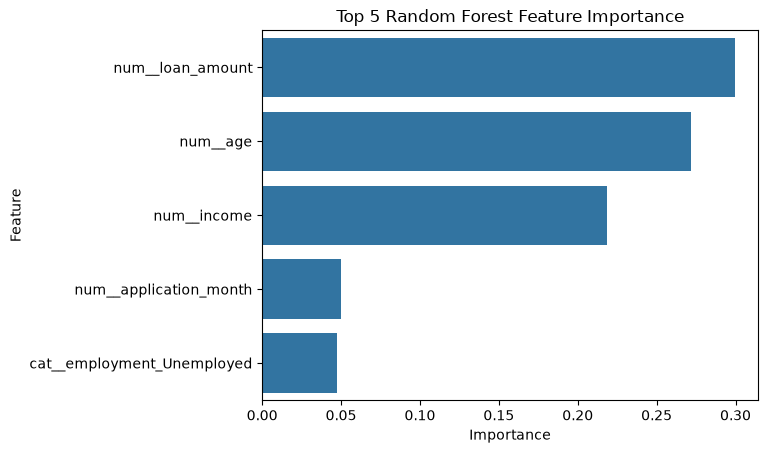

In [7]:

rf_model = trained_models["Random Forest"]

feature_names = rf_model.named_steps[
    "preprocessor"
].get_feature_names_out()

rf_importance = rf_model.named_steps[
    "classifier"
].feature_importances_

rf_features = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_importance
})

rf_features = rf_features.sort_values(
    by="Importance", ascending=False
).head(5)

print("TOP 5 RANDOM FOREST FEATURES")
print(rf_features)

sns.barplot(
    data=rf_features,
    x="Importance",
    y="Feature"
)
plt.title("Top 5 Random Forest Feature Importance")
plt.show()


TOP 5 XGBOOST FEATURES
                  Feature  Importance
0                num__age         1.0
1             num__income         0.0
2        num__loan_amount         0.0
3   num__application_year         0.0
4  num__application_month         0.0


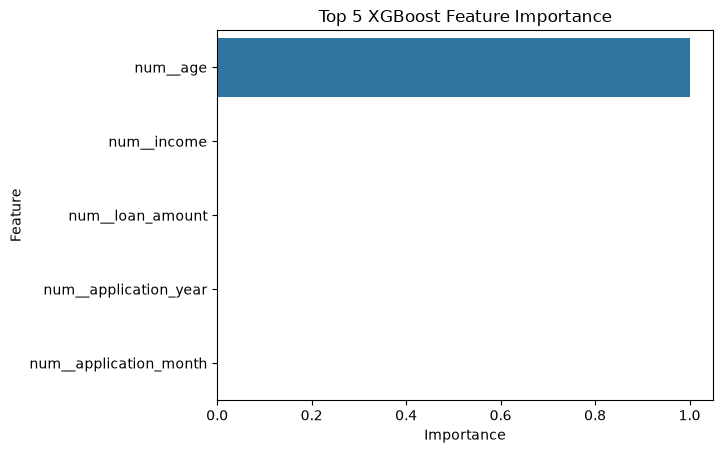

In [8]:

xgb_importance = xgb_pipe.named_steps[
    "classifier"
].feature_importances_

xgb_features = pd.DataFrame({
    "Feature": feature_names,
    "Importance": xgb_importance
})

xgb_features = xgb_features.sort_values(
    by="Importance", ascending=False
).head(5)

print("TOP 5 XGBOOST FEATURES")
print(xgb_features)

sns.barplot(
    data=xgb_features,
    x="Importance",
    y="Feature"
)
plt.title("Top 5 XGBoost Feature Importance")
plt.show()


In [9]:

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score

# Target
X_reg = X.drop(columns=["loan_amount"])
y_reg = df["loan_amount"]

# Train-test split
Xr_train, Xr_val, yr_train, yr_val = train_test_split(
    X_reg, y_reg,
    test_size=0.30,
    random_state=42
)

# Regression preprocessing
reg_numeric = [
    "age", "income",
    "application_year", "application_month"
]

reg_categorical = ["employment", "education"]

reg_preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), reg_numeric),

    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), reg_categorical)
])

# Models
reg_models = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Lasso": Lasso(alpha=0.1, max_iter=10000)
}

reg_results = []
coefficients = {}

for name, model in reg_models.items():

    pipe = Pipeline([
        ("preprocessor", reg_preprocessor),
        ("regressor", model)
    ])

    pipe.fit(Xr_train, yr_train)

    pred = pipe.predict(Xr_val)

    mse = mean_squared_error(yr_val, pred)
    r2 = r2_score(yr_val, pred)

    reg_results.append({
        "Model": name,
        "MSE": mse,
        "R2 Score": r2
    })

    feature_names_reg = pipe.named_steps[
        "preprocessor"
    ].get_feature_names_out()

    coefficients[name] = pipe.named_steps[
        "regressor"
    ].coef_

print(pd.DataFrame(reg_results))

# Compare coefficients
coef_df = pd.DataFrame({
    "Feature": feature_names_reg,
    "Linear Regression": coefficients["Linear Regression"],
    "Ridge": coefficients["Ridge"],
    "Lasso": coefficients["Lasso"]
})

print("\nCOEFFICIENT COMPARISON")
print(coef_df.to_string(index=False))

# Count zero Lasso coefficients
zero_count = np.sum(
    np.isclose(coefficients["Lasso"], 0)
)

print("\nNumber of zero Lasso coefficients:", zero_count)


               Model           MSE  R2 Score
0  Linear Regression  2.905270e+06  0.966659
1              Ridge  3.703949e+06  0.957494
2              Lasso  2.902434e+06  0.966692

COEFFICIENT COMPARISON
                      Feature  Linear Regression       Ridge        Lasso
                     num__age        1686.820167 2956.496805  1687.937319
                  num__income        8147.307591 5434.067279  8145.164597
        num__application_year         -89.541445 -385.220837   -89.747995
       num__application_month         116.675979 -334.481152   116.212281
     cat__employment_Salaried        -144.180355  249.120034  -858.596119
cat__employment_Self-employed        -900.880462 -409.410809 -1614.978236
   cat__employment_Unemployed        1045.060817  160.290774  1882.183849
      cat__education_Graduate        -308.554987 -809.911861   367.165145
   cat__education_High School        1045.060817  160.290774   167.685477
  cat__education_Postgraduate        -736.505829  649.62

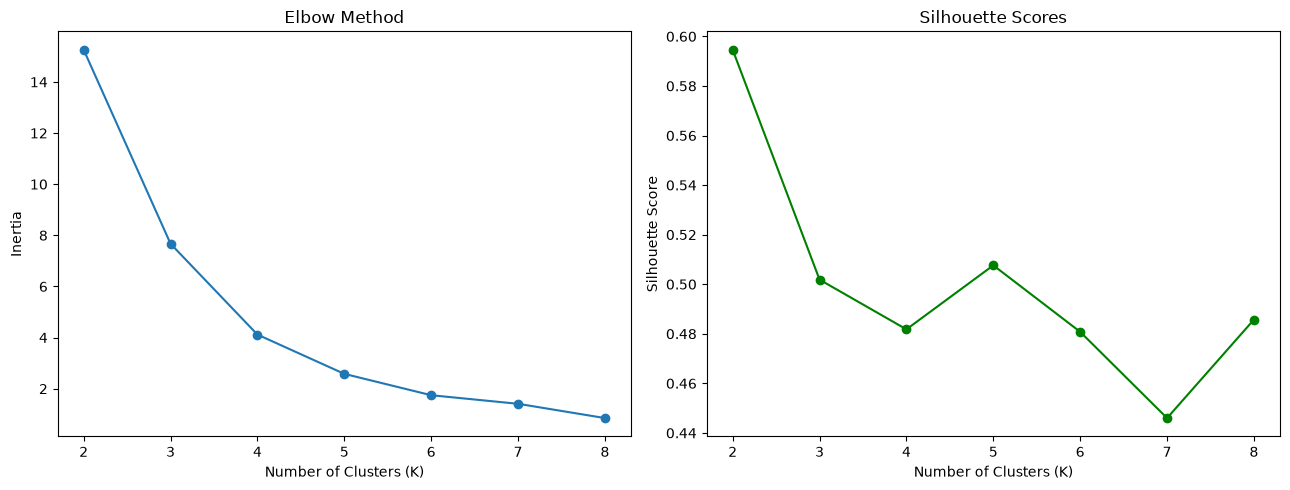

   K    Inertia  Silhouette Score
0  2  15.259412          0.594611
1  3   7.670098          0.501846
2  4   4.116999          0.481796
3  5   2.580462          0.507625
4  6   1.744877          0.480793
5  7   1.409532          0.445996
6  8   0.850709          0.485727

Best K based on Silhouette Score: 2

CLUSTER SEGMENT DESCRIPTION
           age   income  loan_amount  loan_status
Cluster                                          
0        32.09  45000.0      15000.0         0.33
1        47.00  84125.0      31875.0         1.00


In [10]:

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Select numeric columns
cluster_data = df[
    ["age", "income", "loan_amount"]
]

# Handle missing values
imputer = SimpleImputer(strategy="median")
cluster_imputed = imputer.fit_transform(cluster_data)

# Scale features
scaler = StandardScaler()
cluster_scaled = scaler.fit_transform(cluster_imputed)

# Test K from 2 to 8
inertia_values = []
silhouette_values = []

for k in range(2, 9):

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(cluster_scaled)

    inertia_values.append(kmeans.inertia_)

    silhouette_values.append(
        silhouette_score(cluster_scaled, labels)
    )

# Plot elbow and silhouette curves
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(
    range(2, 9),
    inertia_values,
    marker="o"
)
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of Clusters (K)")
axes[0].set_ylabel("Inertia")

axes[1].plot(
    range(2, 9),
    silhouette_values,
    marker="o",
    color="green"
)
axes[1].set_title("Silhouette Scores")
axes[1].set_xlabel("Number of Clusters (K)")
axes[1].set_ylabel("Silhouette Score")

plt.tight_layout()
plt.show()

# Display scores
cluster_results = pd.DataFrame({
    "K": range(2, 9),
    "Inertia": inertia_values,
    "Silhouette Score": silhouette_values
})

print(cluster_results)

# Select K with highest silhouette score
best_k = list(range(2, 9))[
    np.argmax(silhouette_values)
]

print("\nBest K based on Silhouette Score:", best_k)

# Train final K-Means model
final_kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

df["Cluster"] = final_kmeans.fit_predict(
    cluster_scaled
)

# Describe customer segments
cluster_summary = df.groupby("Cluster").agg({
    "age": "mean",
    "income": "mean",
    "loan_amount": "mean",
    "loan_status": "mean"
}).round(2)

print("\nCLUSTER SEGMENT DESCRIPTION")
print(cluster_summary)


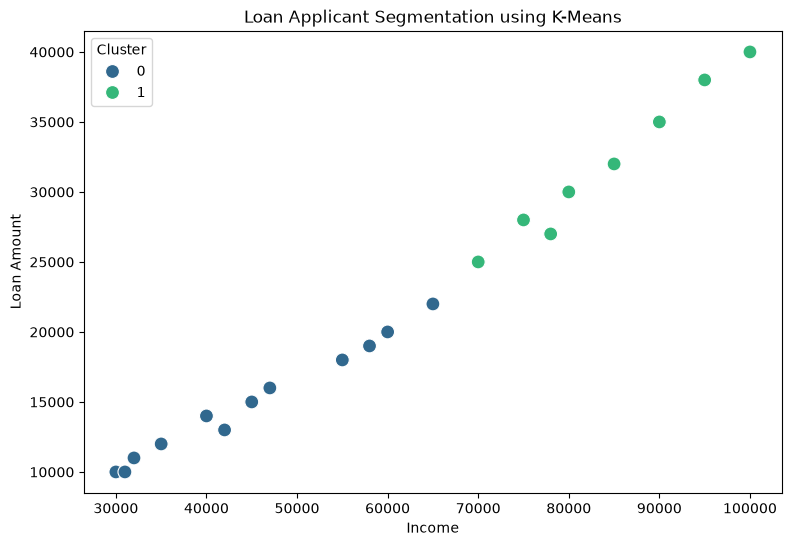

In [11]:

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="income",
    y="loan_amount",
    hue="Cluster",
    palette="viridis",
    s=100
)

plt.title("Loan Applicant Segmentation using K-Means")
plt.xlabel("Income")
plt.ylabel("Loan Amount")
plt.show()
